# NB05 — Stage-2 Full-Pool Refit + DENTEX Eval

**Prerequisite:** NB04 Part 1 is **FROZEN** (5-fold CV + ablation + `stage2_part1_negative_report.json`).
Do **not** retrain folds. Primary detection claims stay with NB04 CV.

**Phase A (refit):** Train **one** Stage-2 gaze model on the **full CV pool** (`train_split.csv`, ~900).
Epoch budget = median best epoch from NB04 fold histories (or `refit_epochs` in config).
**No early stopping on the held-out test.** Test metrics are **secondary** only.

| Output | Role |
|---|---|
| `checkpoints/stage2_refit_best.pth` | Final model for NB06 faithfulness + taxonomy |
| `results/stage2_refit_metrics.json` | Secondary held-out test (not primary CV claim) |

**Phase B (DENTEX):** Zero-shot / cross-domain eval. Checkpoint resolve order:
1. `stage2_refit_best.pth`
2. best NB04 fold (`stage2_gaze_fold*_best.pth` via `stage2_cv_fold_metrics.json`)
3. legacy `stage2_best.pth` (optional only)

**Ignore any old NB04 DENTEX AUROC~0.45 table** — re-run here after refit.

---
### Colab re-run order (GPU)
1. Mount Drive
2. Setup cell (`PROJECT` / `LOCAL_DATA`)
3. Zip cell (local images)
4. **Deps cell** (`torchao>=0.16`) → if Colab asks, **Runtime → Restart session**, then remount and re-run 1–4
5. Refit cell
6. DENTEX cells (loader → preflight → full eval)


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# === Colab setup (plan §1.2) ===
try:
    from google.colab import drive
except ImportError:
    pass

import os, sys, json, glob, shutil, zipfile
import torch

PROJECT = '/content/drive/MyDrive/DENTAL'
NOTEBOOKS_DIR = os.path.join(PROJECT, 'Notebooks')
CODE_DIR = '/content/dental_code'
LOCAL_DATA = '/content/dental_data'
LOCAL_ZIP_CACHE = '/content/dental_zip_cache'
os.makedirs(CODE_DIR, exist_ok=True)
os.makedirs(LOCAL_DATA, exist_ok=True)
os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)

# Prefer Drive modules over stale /content/dental_code copies
sys.path = [p for p in sys.path if p not in (CODE_DIR, PROJECT, NOTEBOOKS_DIR)]
sys.path.insert(0, CODE_DIR)
sys.path.insert(0, NOTEBOOKS_DIR)
sys.path.insert(0, PROJECT)
os.chdir(PROJECT)

with open('config.json', 'r') as f:
    CONFIG = json.load(f)

ON_GPU = torch.cuda.is_available()
device = torch.device('cuda' if ON_GPU else 'cpu')
SMOKE_TEST = False
RESUME_TRAINING = bool(CONFIG.get('resume_training', True))
NUM_WORKERS = 2 if ON_GPU else 0

print('Working directory:', os.getcwd())
print('LOCAL_DATA:', LOCAL_DATA, '| ZIP cache:', LOCAL_ZIP_CACHE)
print('ON_GPU:', ON_GPU, '| device:', device, '| RESUME_TRAINING:', RESUME_TRAINING)
print('Resolution:', CONFIG['chosen_resolution'], '| batch:', CONFIG['chosen_batch_size'])


Working directory: /content/drive/.shortcut-targets-by-id/1N3UUheuN9X0pGAg7NqIleZ74w80yddyz/DENTAL
LOCAL_DATA: /content/dental_data | ZIP cache: /content/dental_zip_cache
ON_GPU: True | device: cuda | RESUME_TRAINING: True
Resolution: 224 | batch: 64


In [7]:
# === Local images from Drive zip archives (NB04 contract) ===
# Drive (PROJECT): splits/, gaze_maps_48x48/, checkpoints/, results/, config.json
# Local (LOCAL_DATA): data/ only — unzipped from PROJECT/Data zip/*.zip
# No image copytree.
import os, glob, shutil, zipfile

if 'PROJECT' not in globals():
    raise RuntimeError('PROJECT not set — run setup cell first')
if 'LOCAL_DATA' not in globals():
    LOCAL_DATA = '/content/dental_data'
if 'LOCAL_ZIP_CACHE' not in globals():
    LOCAL_ZIP_CACHE = '/content/dental_zip_cache'

DATA_ZIP_DIR = os.path.join(PROJECT, 'Data zip')
DATA_MARKER = os.path.join(LOCAL_DATA, 'data', 'tdd', 'Expert', 'expert.json')
DENTEX_MARKER = os.path.join(LOCAL_DATA, 'data', 'dentex')


def ensure_drive_metadata():
    required = [
        'splits/train_split.csv',
        'splits/test_split.csv',
        'splits/dentex_test_split.csv',
        'gaze_maps_48x48',
        'dental_dataset.py',
        'core_modules.py',
        'stage2_refit.py',
    ]
    missing = [p for p in required if not os.path.exists(os.path.join(PROJECT, p))]
    if missing:
        raise FileNotFoundError('Missing on Drive: ' + ', '.join(missing))


def ensure_local_images_from_zip():
    """Copy zip shards Drive -> local cache, unzip into LOCAL_DATA/data/."""
    os.makedirs(LOCAL_DATA, exist_ok=True)
    os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)
    ensure_drive_metadata()

    if os.path.exists(DATA_MARKER):
        print(f'Local images already present: {os.path.join(LOCAL_DATA, "data")}')
        print(f'Metadata on Drive: {PROJECT}')
        if not os.path.isdir(DENTEX_MARKER):
            print(f'WARNING: DENTEX folder missing at {DENTEX_MARKER} — check zip contents')
        else:
            print(f'DENTEX local: {DENTEX_MARKER}')
        return

    if not os.path.isdir(DATA_ZIP_DIR):
        raise FileNotFoundError(f'Missing zip folder: {DATA_ZIP_DIR}')

    zip_on_drive = sorted(glob.glob(os.path.join(DATA_ZIP_DIR, '*.zip')))
    if not zip_on_drive:
        raise FileNotFoundError(f'No .zip files in {DATA_ZIP_DIR}')

    for src_zip in zip_on_drive:
        name = os.path.basename(src_zip)
        dst_zip = os.path.join(LOCAL_ZIP_CACHE, name)
        if (not os.path.exists(dst_zip)) or os.path.getsize(dst_zip) != os.path.getsize(src_zip):
            print(f'Copying zip Drive -> local cache: {name}')
            shutil.copy2(src_zip, dst_zip)
        else:
            print(f'Zip cache hit: {name}')
        print(f'Unzipping {name} -> {LOCAL_DATA} ...')
        with zipfile.ZipFile(dst_zip, 'r') as zf:
            zf.extractall(LOCAL_DATA)

    if not os.path.exists(DATA_MARKER):
        raise FileNotFoundError(
            'Unzip finished but data/tdd/Expert/expert.json missing. '
            'Zip archives must contain a top-level data/ folder.'
        )
    print(f'Local images ready: {os.path.join(LOCAL_DATA, "data")}')
    if os.path.isdir(DENTEX_MARKER):
        print(f'DENTEX local: {DENTEX_MARKER}')
    else:
        print(f'WARNING: DENTEX folder missing at {DENTEX_MARKER}')
    print(f'Splits + gaze + artifacts on Drive: {PROJECT}')


ensure_local_images_from_zip()


Local images already present: /content/dental_data/data
Metadata on Drive: /content/drive/MyDrive/DENTAL
DENTEX local: /content/dental_data/data/dentex


## A — Full-pool Stage-2 refit (GPU)

Trains on **all** `train_split` images (~900). Held-out `test_split` (100) is evaluated **once at the end** for a secondary table. Resume: `checkpoints/stage2_refit_last.pth`.


In [8]:
# === Install deps BEFORE refit (peft needs torchao>=0.16) ===
# If this cell upgrades packages, Colab may require:
#   Runtime → Restart session
# Then remount Drive and re-run: setup → this deps cell → zip → refit
import sys
import subprocess

pkgs = [
    'torchao>=0.16.0',
    'peft',
    'transformers',
    'scikit-learn',
    'pandas',
    'numpy',
    'tqdm',
    'pillow',
    'opencv-python',
    'matplotlib',
    'packaging',
]
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *pkgs])

import importlib.metadata as md
from packaging.version import Version

torchao_v = md.version('torchao')
peft_v = md.version('peft')
print('torchao', torchao_v, '| peft', peft_v)
if Version(torchao_v) < Version('0.16.0'):
    raise RuntimeError(
        f'torchao {torchao_v} still < 0.16.0. '
        'Runtime → Restart session, then re-run setup + this cell.'
    )
print('Deps OK for LoRA/peft.')


torchao 0.18.0 | peft 0.19.1
Deps OK for LoRA/peft.


In [9]:
# === Full-pool Stage-2 refit ===
import os
import sys
import json
import shutil
import importlib.metadata as md
from packaging.version import Version

if 'torch' not in globals():
    import torch
if 'ON_GPU' not in globals() or 'device' not in globals():
    ON_GPU = torch.cuda.is_available()
    device = torch.device('cuda' if ON_GPU else 'cpu')
if 'SMOKE_TEST' not in globals():
    SMOKE_TEST = False
if 'RESUME_TRAINING' not in globals():
    RESUME_TRAINING = True
if 'PROJECT' not in globals():
    raise RuntimeError('PROJECT not set — run setup cell first')
if 'LOCAL_DATA' not in globals():
    LOCAL_DATA = '/content/dental_data'
if 'CODE_DIR' not in globals():
    CODE_DIR = '/content/dental_code'
if 'CONFIG' not in globals():
    with open(os.path.join(PROJECT, 'config.json'), 'r', encoding='utf-8') as f:
        CONFIG = json.load(f)

# Hard stop if deps cell / restart was skipped
torchao_v = md.version('torchao')
if Version(torchao_v) < Version('0.16.0'):
    raise RuntimeError(
        f'torchao {torchao_v} < 0.16.0 — run the deps cell, Restart session, then retry.'
    )

if not os.path.isdir(os.path.join(LOCAL_DATA, 'data')):
    raise FileNotFoundError(
        f'LOCAL_DATA missing images at {LOCAL_DATA}/data — run the zip cell first.'
    )

# Refresh code modules from Drive into CODE_DIR
os.makedirs(CODE_DIR, exist_ok=True)
for fname in (
    'stage2_refit.py', 'stage2_train_utils.py', 'stage2_cv.py',
    'negative_result_stats.py', 'core_modules.py', 'dental_dataset.py',
):
    src = os.path.join(PROJECT, fname)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(CODE_DIR, fname))

for mod in (
    'stage2_refit', 'stage2_train_utils', 'stage2_cv', 'negative_result_stats',
    'core_modules', 'dental_dataset',
):
    if mod in sys.modules:
        del sys.modules[mod]

# Prefer Drive project root, then CODE_DIR
sys.path = [p for p in sys.path if p not in (CODE_DIR, PROJECT)]
sys.path.insert(0, CODE_DIR)
sys.path.insert(0, PROJECT)

from stage2_refit import run_stage2_refit

os.chdir(PROJECT)
print(f'Refit start | train images root={LOCAL_DATA} | resume={RESUME_TRAINING} | smoke={SMOKE_TEST}')
refit_out = run_stage2_refit(
    CONFIG,
    PROJECT,
    LOCAL_DATA,
    device,
    smoke_test=SMOKE_TEST,
    resume=RESUME_TRAINING,
    on_gpu=ON_GPU,
)
print('Refit done:', refit_out.get('train_done'), '| ckpt:', refit_out.get('checkpoint'))


Refit start | train images root=/content/dental_data | resume=True | smoke=False
Anomaly mask check: OK: 32/32 lesion samples have mask pixels; 0/8 healthy samples nonzero (expect 0)
Refit train pool: 900 | held-out test: 100
Refit epochs=17 (cv_median_best_epoch=16)


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
 [INFO] Loaded Stage 1 weights from checkpoints/stage1_best.pth (epoch 20): <All keys matched successfully>


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

...

REFIT E16/16: 100%|██████████| 42/42 [01:21<00:00,  1.94s/batch, loss=1.0907]


REFIT E16: loss=1.0907 (main=0.8167, kl=1.5763, aux=0.0525)
Saved checkpoints/stage2_refit_best.pth


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
 [INFO] Loaded Stage 1 weights from checkpoints/stage1_best.pth (epoch 20): <All keys matched successfully>

=== Refit secondary TEST (not primary CV claim) ===
  Stage1 AUROC: 0.5847
  Refit  AUROC: 0.6217
  No significant Stage 2 improvement over Stage 1 (supports negative/null result)
Saved /content/drive/MyDrive/DENTAL/results/stage2_refit_metrics.json
Refit done: True | ckpt: checkpoints/stage2_refit_best.pth


In [10]:
print('Zip cache preserved (no wipe).')


Zip cache preserved (no wipe).


In [11]:
pass  # legacy wipe cell removed


## 1 — Runtime setup & mode selection

`ON_GPU` drives the whole notebook. CPU = code-validation dry run only; GPU = real
DENTEX eval. `NUM_WORKERS` matches NB03/NB04.

In [12]:
import random
import numpy as np
import torch
import shutil
from tqdm.auto import tqdm
# # import cv2
import pandas as pd
# # from PIL import Image
from torch.utils.data import DataLoader

SEED = int(CONFIG.get('random_seed', 42))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ON_GPU = torch.cuda.is_available()
NUM_WORKERS = 0  # Colab multiprocessing guard — same fix as NB04 (child process AssertionError)

os.makedirs('results', exist_ok=True)

# Sentinel flags — initialised here so §7/§9 cells never NameError if an
# earlier cell fails before setting them (CRITICAL-2 fix).
CODE_CHECK_PASSED = False
REAL_EVAL_DONE = False
status = {}  # populated by §7; guard against out-of-order cell execution
stage2_dentex_metrics = None
baseline_metrics = None

if ON_GPU:
    print(f'>>> GPU detected ({torch.cuda.get_device_name(0)}) — REAL DENTEX eval will run.')
else:
    print('>>> NO GPU detected — running CODE-VALIDATION DRY RUN only (no full eval).')

>>> GPU detected (Tesla T4) — REAL DENTEX eval will run.


## 2 — Local images via Drive zip cache (no copytree)

Same contract as NB04:
- Drive (`PROJECT`): splits, gaze maps, checkpoints, results, config
- Local (`LOCAL_DATA=/content/dental_data`): `data/` only from `PROJECT/Data zip/*.zip`
- Zip shards under `/content/dental_zip_cache`

Re-run the zip ensure cell below if runtime was restarted.


In [13]:
# Re-run zip ensure (idempotent). No image copytree.
import os, glob, shutil, zipfile

if 'LOCAL_DATA' not in globals():
    LOCAL_DATA = '/content/dental_data'
if 'LOCAL_ZIP_CACHE' not in globals():
    LOCAL_ZIP_CACHE = '/content/dental_zip_cache'
if 'ensure_local_images_from_zip' not in globals():
    DATA_ZIP_DIR = os.path.join(PROJECT, 'Data zip')
    DATA_MARKER = os.path.join(LOCAL_DATA, 'data', 'tdd', 'Expert', 'expert.json')
    DENTEX_MARKER = os.path.join(LOCAL_DATA, 'data', 'dentex')

    def ensure_drive_metadata():
        required = [
            'splits/train_split.csv',
            'splits/test_split.csv',
            'splits/dentex_test_split.csv',
            'gaze_maps_48x48',
            'dental_dataset.py',
            'core_modules.py',
            'stage2_refit.py',
        ]
        missing = [p for p in required if not os.path.exists(os.path.join(PROJECT, p))]
        if missing:
            raise FileNotFoundError('Missing on Drive: ' + ', '.join(missing))

    def ensure_local_images_from_zip():
        os.makedirs(LOCAL_DATA, exist_ok=True)
        os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)
        ensure_drive_metadata()
        if os.path.exists(DATA_MARKER):
            print(f'Local images already present: {os.path.join(LOCAL_DATA, "data")}')
            return
        if not os.path.isdir(DATA_ZIP_DIR):
            raise FileNotFoundError(f'Missing zip folder: {DATA_ZIP_DIR}')
        zip_on_drive = sorted(glob.glob(os.path.join(DATA_ZIP_DIR, '*.zip')))
        if not zip_on_drive:
            raise FileNotFoundError(f'No .zip files in {DATA_ZIP_DIR}')
        for src_zip in zip_on_drive:
            name = os.path.basename(src_zip)
            dst_zip = os.path.join(LOCAL_ZIP_CACHE, name)
            if (not os.path.exists(dst_zip)) or os.path.getsize(dst_zip) != os.path.getsize(src_zip):
                print(f'Copying zip Drive -> local cache: {name}')
                shutil.copy2(src_zip, dst_zip)
            else:
                print(f'Zip cache hit: {name}')
            print(f'Unzipping {name} -> {LOCAL_DATA} ...')
            with zipfile.ZipFile(dst_zip, 'r') as zf:
                zf.extractall(LOCAL_DATA)
        if not os.path.exists(DATA_MARKER):
            raise FileNotFoundError('Unzip finished but data/tdd/Expert/expert.json missing.')
        print(f'Local images ready: {os.path.join(LOCAL_DATA, "data")}')

ensure_local_images_from_zip()
if not os.path.exists(os.path.join(PROJECT, 'splits', 'train_split.csv')):
    raise FileNotFoundError('Run NB00_prep.ipynb — splits/train_split.csv not on Drive.')
print(f'Images: {LOCAL_DATA}/data/  |  splits/gaze: {PROJECT}')
print(f'Working dir: {os.getcwd()} (artifacts write to Drive)')


Local images already present: /content/dental_data/data
Metadata on Drive: /content/drive/MyDrive/DENTAL
DENTEX local: /content/dental_data/data/dentex
Images: /content/dental_data/data/  |  splits/gaze: /content/drive/MyDrive/DENTAL
Working dir: /content/drive/.shortcut-targets-by-id/1N3UUheuN9X0pGAg7NqIleZ74w80yddyz/DENTAL (artifacts write to Drive)


## 3 — Dataset & DataLoader

`DualArmGazeDataset` reused from NB03/NB04 (DENTEX rows carry `has_gaze_map=0`, so the
gaze channel is just zeros — correct for a no-gaze held-out set). On CPU we cap the
loader to a handful of samples so the code check finishes in seconds.

In [14]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

from dental_dataset import DentalDataset

DENTEX_LIMIT = 32 if not ON_GPU else None  # one full batch on CPU (batch_size=32)

dentex_ds = DentalDataset(f'{PROJECT}/splits/dentex_test_split.csv', PROJECT, image_root=LOCAL_DATA, augment=False)
dentex_ds.df = dentex_ds.df[dentex_ds.df['has_lesion_gt'].isin([0, 1])].reset_index(drop=True)

if DENTEX_LIMIT:
    dentex_ds.df = dentex_ds.df.head(DENTEX_LIMIT).reset_index(drop=True)

dentex_loader = DataLoader(dentex_ds, batch_size=CONFIG['chosen_batch_size'],
                           shuffle=False, num_workers=NUM_WORKERS, pin_memory=ON_GPU)
print(f'DENTEX split: {len(dentex_ds)} images | batch: {CONFIG["chosen_batch_size"]}')


DENTEX split: 1005 images | batch: 64


## 4 — Model builders + the DENTEX eval routine

`build_model(cfg)` wraps the NB01 `SwinGazeModel` build so both models are constructed
identically. `run_dentex_eval` uses `sigmoid(logits.squeeze(-1))` — `logits` is already
pooled to `[B, 1]` by the model — for one probability per image, and returns per-image
targets/preds/probs plus the image ids so the saved CSVs can be matched back to DENTEX rows.

In [15]:
from core_modules import SwinGazeModel, compute_metrics


def build_model(cfg):
    """Build SwinGazeModel from cfg and move to device."""
    return SwinGazeModel(cfg).to(device)


def run_dentex_eval(mdl, loader):
    """Return (ids, targets, preds, probs) over loader using pooled logits.

    NB: plan §7.4 used sigmoid(logits.squeeze()), which thresholds pixels not images.
    We pool to one logit per image first, consistent with how the models were trained.
    """
    mdl.eval()
    preds, targets, probs, ids = [], [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc='DENTEX eval', leave=False):
            logits, seg_map, _, _ = mdl(batch['image'].to(device))
            p = torch.sigmoid(logits.squeeze(-1)).cpu().numpy()
            preds.extend((p > 0.5).astype(int).tolist())
            probs.extend(p.tolist())
            targets.extend(batch['has_lesion_gt'].tolist())
            ids.extend(batch.get('id', batch.get('image_id', [])))
    return np.array(ids), np.array(targets), np.array(preds), np.array(probs)

## 5 — Pre-flight code check (always runs)

Build the Stage-2 model, load the best available Stage-2 checkpoint (refit → best CV fold →
legacy → else Stage-1 for dry-run only), run `run_dentex_eval` on the DENTEX loader, and
assert finite metrics + CSV columns expected by NB07.


In [16]:
# --- resolve Stage-2 checkpoint (refit > best CV fold > legacy) --------------
import json as _json

def resolve_stage2_ckpt(project='.'):
    candidates = [
        f'{project}/checkpoints/stage2_refit_best.pth',
        f'{project}/checkpoints/stage2_best.pth',
    ]
    metrics_path = f'{project}/results/stage2_cv_fold_metrics.json'
    if os.path.isfile(metrics_path):
        with open(metrics_path, 'r', encoding='utf-8') as f:
            rows = _json.load(f)
        if rows:
            best = max(rows, key=lambda r: float(r.get('val_AUROC', -1)))
            ck = best.get('checkpoint') or f"checkpoints/stage2_gaze_fold{best['fold']}_best.pth"
            candidates.insert(1, ck if os.path.isabs(ck) else f'{project}/{ck}')
    for p in candidates:
        p = os.path.normpath(p)
        if os.path.isfile(p):
            return p
    return None

STAGE1_CKPT = 'checkpoints/stage1_best.pth'
STAGE2_CKPT = resolve_stage2_ckpt('.')
print(f'  {STAGE1_CKPT}: {"present" if os.path.isfile(STAGE1_CKPT) else "MISSING"}')
print(f'  STAGE2 resolved: {STAGE2_CKPT or "MISSING"}')
if not os.path.isfile(STAGE1_CKPT):
    raise FileNotFoundError(f'{STAGE1_CKPT} not found — run NB03 first on a GPU runtime.')

preflight_ckpt = STAGE2_CKPT if STAGE2_CKPT else STAGE1_CKPT
print(f'Pre-flight will load: {preflight_ckpt}')

pf_model = build_model(CONFIG)
pf_state = torch.load(preflight_ckpt, map_location=device, weights_only=True)
pf_state = pf_state['model'] if isinstance(pf_state, dict) and 'model' in pf_state else pf_state
pf_model.load_state_dict(pf_state, strict=False)

ids, targets, preds, probs = run_dentex_eval(pf_model, dentex_loader)
assert len(ids) == len(targets) == len(preds) == len(probs), 'eval arrays length mismatch'
assert probs.ndim == 1, f'probs must be 1-D per-image, got {probs.shape}'

m = compute_metrics(targets, preds, probs)
assert all(np.isfinite(v) for v in m.values()), 'preflight metrics not finite'

sample_df = pd.DataFrame({'has_lesion_gt': targets, 'model_pred': preds, 'probs': probs})
assert list(sample_df.columns) == ['has_lesion_gt', 'model_pred', 'probs'], sample_df.columns.tolist()

CODE_CHECK_PASSED = True
print(f'Pre-flight DENTEX eval OK | n={len(ids)} | '
      f'metrics={{{", ".join(f"{k}={float(v):.4f}" for k, v in m.items())}}}')
print(f'Sample CSV columns OK: {sample_df.columns.tolist()}')
del pf_model
torch.cuda.empty_cache() if ON_GPU else None
print('CODE CHECK PASSED')


  checkpoints/stage1_best.pth: present
  STAGE2 resolved: checkpoints/stage2_refit_best.pth
Pre-flight will load: checkpoints/stage2_refit_best.pth


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DENTEX eval:   0%|          | 0/16 [00:00<?, ?it/s]

Pre-flight DENTEX eval OK | n=1005 | metrics={Dice=0.9617, F1=0.9617, Recall=0.9936, AUROC=0.4819}
Sample CSV columns OK: ['has_lesion_gt', 'model_pred', 'probs']
CODE CHECK PASSED


## 6 — Real DENTEX cross-domain eval (GPU only)

On GPU: evaluate **both** the Gaze model (Stage 2) and the Stage-1 baseline over the
*full* DENTEX split, and write the three manifest artifacts + a summary print. On CPU
this block is skipped — only the §5 pre-flight check runs.

In [17]:
REAL_EVAL_DONE = True

if not ON_GPU:
    print('SKIPPING full DENTEX eval — CPU dry run. (run_dentex_eval was validated by the '
          '§5 pre-flight check; no artifacts will be written.)')
else:
    if STAGE2_CKPT is None or not os.path.isfile(STAGE2_CKPT):
        raise FileNotFoundError(
            'No Stage-2 checkpoint. Run Phase A refit (stage2_refit_best.pth) or finish NB04 folds.'
        )
    print(f'Using Stage-2 checkpoint: {STAGE2_CKPT}')

    # --- Gaze model (Stage 2) --------------------------------------------------
    model = build_model(CONFIG)
    s2_state = torch.load(STAGE2_CKPT, map_location=device, weights_only=True)
    s2_state = s2_state['model'] if isinstance(s2_state, dict) and 'model' in s2_state else s2_state
    model.load_state_dict(s2_state, strict=False)
    print(f'Evaluating Stage-2 on full DENTEX ({len(dentex_ds)} images) ...')
    ids, targets, preds, probs = run_dentex_eval(model, dentex_loader)
    stage2_dentex_metrics = compute_metrics(targets, preds, probs)
    stage2_dentex_metrics['checkpoint'] = STAGE2_CKPT
    with open('results/dentex_cross_domain_metrics.json', 'w') as f:
        json.dump(stage2_dentex_metrics, f, indent=4, default=float)
    pd.DataFrame({'has_lesion_gt': targets, 'model_pred': preds, 'probs': probs}).to_csv(
        'results/dentex_per_image_predictions.csv', index=False)
    print('Stage-2 DENTEX:', {k: round(float(v), 4) for k, v in stage2_dentex_metrics.items() if k != 'checkpoint'})
    print('Saved results/dentex_cross_domain_metrics.json + dentex_per_image_predictions.csv')
    del model
    torch.cuda.empty_cache()

    # --- Stage-1 baseline (no gaze) — required by NB07 §7.3 ------------------
    baseline = build_model(CONFIG)
    s1_state = torch.load(STAGE1_CKPT, map_location=device, weights_only=True)
    s1_state = s1_state['model'] if isinstance(s1_state, dict) and 'model' in s1_state else s1_state
    baseline.load_state_dict(s1_state, strict=False)
    print(f'Evaluating Stage-1 baseline on full DENTEX ({len(dentex_ds)} images) ...')
    b_ids, b_targets, b_preds, b_probs = run_dentex_eval(baseline, dentex_loader)
    baseline_metrics = compute_metrics(b_targets, b_preds, b_probs)
    pd.DataFrame({'has_lesion_gt': b_targets, 'model_pred': b_preds, 'probs': b_probs}).to_csv(
        'results/dentex_baseline_predictions.csv', index=False)
    print('Stage-1 baseline DENTEX:', {k: round(float(v), 4) for k, v in baseline_metrics.items()})
    print('Saved results/dentex_baseline_predictions.csv')
    del baseline
    torch.cuda.empty_cache()

    REAL_EVAL_DONE = True
    print('\nREAL DENTEX cross-domain eval COMPLETE.')


Using Stage-2 checkpoint: checkpoints/stage2_refit_best.pth


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Evaluating Stage-2 on full DENTEX (1005 images) ...


DENTEX eval:   0%|          | 0/16 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Evaluating Stage-1 baseline on full DENTEX (1005 images) ...


DENTEX eval:   0%|          | 0/16 [00:00<?, ?it/s]

Stage-1 baseline DENTEX: {'Dice': 0.0, 'F1': 0.0, 'Recall': 0.0, 'AUROC': 0.518}
Saved results/dentex_baseline_predictions.csv

REAL DENTEX cross-domain eval COMPLETE.


## 7 — Save run status (always written)

`dentex_cross_domain_status.json` so downstream notebooks (NB07) can tell a real
cross-domain eval from a CPU dry run.

In [18]:
status = {
    'mode': 'gpu' if ON_GPU else 'cpu',
    'stage2_ckpt_used': str(STAGE2_CKPT),
    'real_eval_done': bool(REAL_EVAL_DONE),
    'code_check_passed': bool(CODE_CHECK_PASSED),
    'n_dentex_images': int(len(dentex_ds)),
    'stage2_dentex_metrics': stage2_dentex_metrics,
    'baseline_dentex_metrics': baseline_metrics,
}
with open('results/dentex_cross_domain_status.json', 'w') as f:
    json.dump(status, f, indent=2, default=float)
print('Saved results/dentex_cross_domain_status.json')
print(json.dumps(status, indent=2, default=float))

Saved results/dentex_cross_domain_status.json
{
  "mode": "gpu",
  "stage2_ckpt_used": "checkpoints/stage2_refit_best.pth",
  "real_eval_done": true,
  "code_check_passed": true,
  "n_dentex_images": 1005,
  "stage2_dentex_metrics": {
    "Dice": 0.9617373269817098,
    "F1": 0.9617373319544984,
    "Recall": 0.9935897435897436,
    "AUROC": 0.4818608324043107,
    "checkpoint": "checkpoints/stage2_refit_best.pth"
  },
  "baseline_dentex_metrics": {
    "Dice": 0.0,
    "F1": 0.0,
    "Recall": 0.0,
    "AUROC": 0.5179765886287625
  }
}


## 8 — Cross-domain summary plot (GPU runs only)

Stage-2 vs Stage-1 baseline Dice/F1/Recall/AUROC on DENTEX, saved as PNG so NB08 can
re-render publication figures from the saved JSONs.

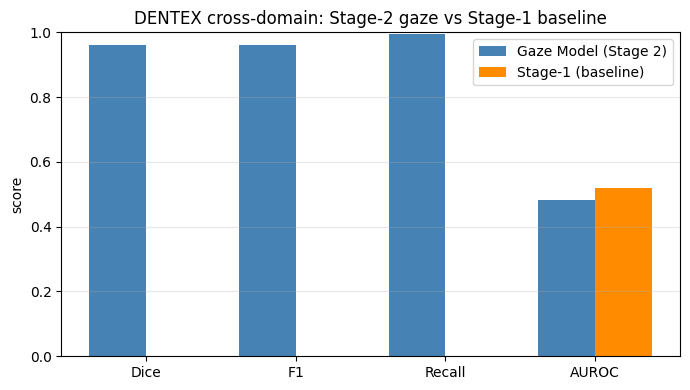

Saved results/dentex_cross_domain_bars.png


In [19]:
if REAL_EVAL_DONE:
    import matplotlib.pyplot as plt

    keys = ['Dice', 'F1', 'Recall', 'AUROC']
    x = np.arange(len(keys))
    w = 0.38
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(x - w/2, [stage2_dentex_metrics[k] for k in keys], w, label='Gaze Model (Stage 2)', color='steelblue')
    ax.bar(x + w/2, [baseline_metrics[k] for k in keys], w, label='Stage-1 (baseline)', color='darkorange')
    ax.set_xticks(x); ax.set_xticklabels(keys)
    ax.set_ylim(0, 1); ax.set_ylabel('score')
    ax.set_title('DENTEX cross-domain: Stage-2 gaze vs Stage-1 baseline')
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('results/dentex_cross_domain_bars.png', dpi=150)
    plt.show()
    print('Saved results/dentex_cross_domain_bars.png')
else:
    print('No cross-domain plot — CPU dry run (no metrics to plot).')

## 9 — Final status banner

One unambiguous indicator of what actually happened in this run.

In [20]:
from IPython.display import Markdown, display

if REAL_EVAL_DONE:
    s2 = status['stage2_dentex_metrics'] or {}
    bl = status['baseline_dentex_metrics'] or {}
    banner = f"""
# REAL WORK DONE — GPU DENTEX CROSS-DOMAIN EVAL COMPLETED

Evaluated both models on the full DENTEX split (**{status['n_dentex_images']} images**).

| metric | Gaze Model (Stage 2) | Stage-1 (baseline) |
|---|---|---|
| **Dice** | **{s2.get('Dice', float('nan')):.4f}** | {bl.get('Dice', float('nan')):.4f} |
| **F1** | {s2.get('F1', float('nan')):.4f} | {bl.get('F1', float('nan')):.4f} |
| **Recall** | {s2.get('Recall', float('nan')):.4f} | {bl.get('Recall', float('nan')):.4f} |
| **AUROC** | {s2.get('AUROC', float('nan')):.4f} | {bl.get('AUROC', float('nan')):.4f} |

**Saved:** `results/dentex_cross_domain_metrics.json`, `results/dentex_per_image_predictions.csv`,
`results/dentex_baseline_predictions.csv`.

Proceed to **NB06_faithfulness.ipynb**.
"""
    box = '#' * 64
    print(box)
    print('#  REAL DENTEX CROSS-DOMAIN EVAL COMPLETED')
    print('#  Gaze-model Dice = {:.4f}  |  Stage-1 baseline Dice = {:.4f}'.format(
        s2.get('Dice', float('nan')), bl.get('Dice', float('nan'))))
    print(box)
else:
    banner = f"""
# TEST-ONLY RUN — NO REAL WORK DONE

Code was **validated on CPU** (both models built + weights loaded, run_dentex_eval ran on
a few batches, metrics finite, CSV columns correct) but **no full DENTEX eval was
performed** and no DENTEX artifacts were written.

| | |
|---|---|
| **Mode** | CPU dry run |
| **Code check** | {'PASSED' if status['code_check_passed'] else 'FAILED'} |
| **Real eval** | **NOT performed** |

Re-run this notebook on a **GPU Colab runtime** to get real cross-domain results.
"""
    box = '!' * 64
    print(box)
    print('!!  TEST-ONLY RUN  -  NO DENTEX EVAL WAS PERFORMED  !!')
    print('!!  Code check:', 'PASSED' if status['code_check_passed'] else 'FAILED', '| mode:', status['mode'])
    print('!!  Re-run on a GPU runtime for real results.')
    print(box)

display(Markdown(banner))

################################################################
#  REAL DENTEX CROSS-DOMAIN EVAL COMPLETED
#  Gaze-model Dice = 0.9617  |  Stage-1 baseline Dice = 0.0000
################################################################



# REAL WORK DONE — GPU DENTEX CROSS-DOMAIN EVAL COMPLETED

Evaluated both models on the full DENTEX split (**1005 images**).

| metric | Gaze Model (Stage 2) | Stage-1 (baseline) |
|---|---|---|
| **Dice** | **0.9617** | 0.0000 |
| **F1** | 0.9617 | 0.0000 |
| **Recall** | 0.9936 | 0.0000 |
| **AUROC** | 0.4819 | 0.5180 |

**Saved:** `results/dentex_cross_domain_metrics.json`, `results/dentex_per_image_predictions.csv`,
`results/dentex_baseline_predictions.csv`.

Proceed to **NB06_faithfulness.ipynb**.
